# Question 1 — Lagrangian, dual and primal functions
**EN3330 — Introduction to Engineering Optimization, Assignment 03**

This notebook derives the primal/dual quantities analytically and plots them using NumPy and Matplotlib. The plots are calculated directly from the given equations; no numerical optimization package is needed.

**Problem**

$$\min_{x\in\mathbb R} x^2\quad\text{subject to}\quad x\geq 1.$$

Express the inequality as $h(x)=1-x\leq0$. The Lagrangian is

$$L(\mu,x)=x^2+\mu(1-x),\qquad \mu\geq0.$$

Since $x^2$ increases for $x\geq1$, the optimal feasible point is $x^*=1$, giving $p^*=1$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4.4),
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

## 1(a) — Lagrangian curves and their minima
For fixed $\mu$, complete the square:

$$L(\mu,x)=\left(x-\frac\mu2\right)^2+\mu-\frac{\mu^2}{4}.$$

The square is nonnegative and vanishes at $x(\mu)=\mu/2$. Therefore,

$$\boxed{x(\mu)=\underset{x\in\mathbb R}{\arg\min}\,L(\mu,x)=\frac\mu2},\qquad
\boxed{L(\mu,x(\mu))=\mu-\frac{\mu^2}{4}}.$$

The minimization here is *not* restricted to $x\geq1$; the constraint is represented through the multiplier.

In [2]:
def lagrangian(mu, x):
    return x**2 + mu*(1 - x)

def x_minimizer(mu):
    return mu / 2

multipliers = np.array([0.0, 1.0, 2.0, 3.0])
for mu in multipliers:
    xhat = x_minimizer(mu)
    print(f"mu={mu:g}   x(mu)={xhat:.2f}   L_min={lagrangian(mu, xhat):.2f}   feasible={xhat >= 1}")

mu=0   x(mu)=0.00   L_min=0.00   feasible=False
mu=1   x(mu)=0.50   L_min=0.75   feasible=False
mu=2   x(mu)=1.00   L_min=1.00   feasible=True
mu=3   x(mu)=1.50   L_min=0.75   feasible=True


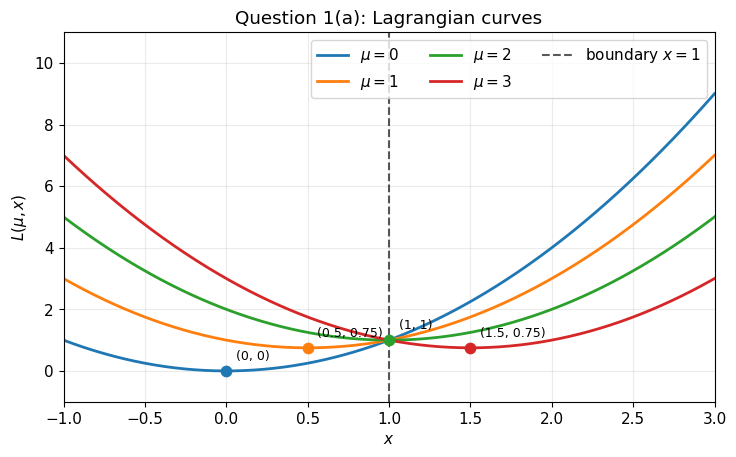

In [3]:
x = np.linspace(-1.0, 3.0, 650)
fig, ax = plt.subplots(figsize=(8.4, 4.8))
for mu in multipliers:
    ax.plot(x, lagrangian(mu, x), linewidth=2, label=rf"$\mu={mu:g}$")
    xhat = x_minimizer(mu)
    ax.scatter(xhat, lagrangian(mu, xhat), s=55, zorder=5)
    ax.annotate(f"({xhat:g}, {lagrangian(mu, xhat):g})",
                (xhat, lagrangian(mu, xhat)), xytext=(7, 8),
                textcoords="offset points", fontsize=9)
ax.axvline(1, linestyle="--", color="black", alpha=.65, label="boundary $x=1$")
ax.set(xlabel="$x$", ylabel=r"$L(\mu,x)$", title="Question 1(a): Lagrangian curves",
       xlim=(-1, 3), ylim=(-1, 11))
ax.legend(ncol=3)
plt.show()

**Interpretation.** The vertex moves right by 0.5 whenever $\mu$ increases by 1. For $\mu=0$ and $1$, the Lagrangian minimizers are infeasible. At $\mu=2$, the minimizer lands on the boundary $x=1$. For $\mu=3$, it moves into the feasible side.

## 1(b) — Dual function and optimum

The dual function is the minimum of the Lagrangian over every real $x$:

$$d(\mu)=\inf_x L(\mu,x)=\mu-\frac{\mu^2}{4}
=1-\frac{(\mu-2)^2}{4},\qquad \mu\geq0.$$

We maximize this concave quadratic over $\mu\geq0$. From $d'(\mu)=1-\mu/2$, the stationary point is $\mu^*=2$. Since $d''(\mu)=-1/2<0$, it is the maximum:

$$\boxed{\mu^*=2,\quad d^*=d(2)=1}.$$

As $p^*=d^*=1$, the duality gap is zero.

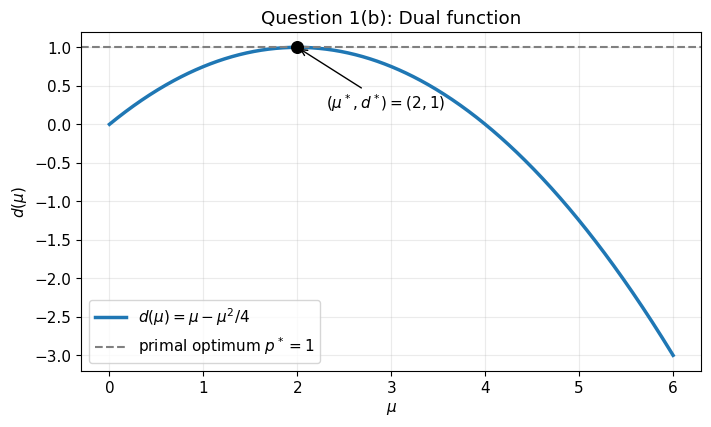

In [4]:
def dual(mu):
    return mu - mu**2 / 4

mu_grid = np.linspace(0, 6, 700)
fig, ax = plt.subplots()
ax.plot(mu_grid, dual(mu_grid), linewidth=2.5, label=r"$d(\mu)=\mu-\mu^2/4$")
ax.axhline(1, color="gray", linestyle="--", label="primal optimum $p^*=1$")
ax.scatter([2], [dual(2)], color="black", zorder=5, s=70)
ax.annotate(r"$(\mu^*,d^*)=(2,1)$", (2, 1), (2.3, .2),
            arrowprops={"arrowstyle": "->"})
ax.set(xlabel=r"$\mu$", ylabel=r"$d(\mu)$", title="Question 1(b): Dual function")
ax.legend()
plt.show()
assert dual(2) == 1

## 1(c) — Primal function and the feasibility barrier

For each fixed $x$,

$$g(x)=\sup_{\mu\geq0} L(\mu,x)=x^2+\sup_{\mu\geq0}\mu(1-x).$$

- When $x\geq1$, the coefficient $1-x\leq0$, so the largest multiplier term is zero.
- When $x<1$, the coefficient $1-x>0$. Increasing $\mu$ without limit sends the Lagrangian to $+\infty$.

Therefore,

$$\boxed{g(x)=\begin{cases} +\infty,&x<1,\\x^2,&x\geq1.\end{cases}}$$

A graph cannot display an infinite numerical value. To illustrate the behavior, limit $\mu$ temporarily to $[0,M]$:

$$g_M(x)=\max_{0\leq\mu\leq M}L(\mu,x)=x^2+M\max(1-x,0).$$

The following curves for $M=3,8,20$ illustrate the increasing penalty on infeasible points; **they are not the exact infinite branch**.

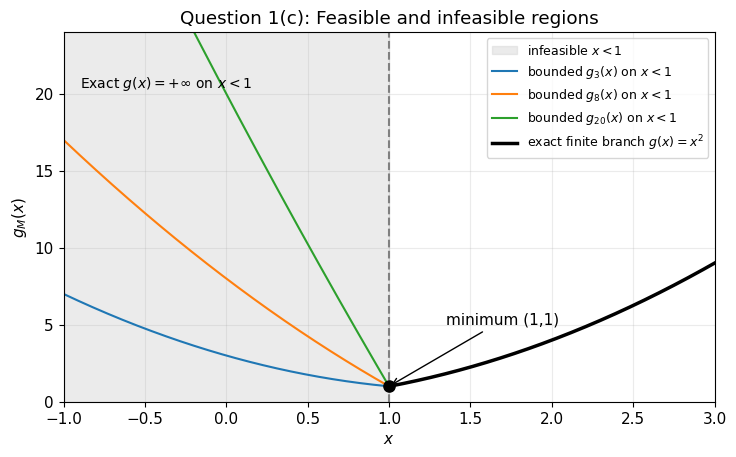

In [5]:
def bounded_primal(x, M):
    return x**2 + M * np.maximum(1 - x, 0)

x = np.linspace(-1, 3, 800)
fig, ax = plt.subplots(figsize=(8.4, 4.8))
ax.axvspan(-1, 1, color="lightgray", alpha=.45, label="infeasible $x<1$")
for M in (3, 8, 20):
    ax.plot(x[x < 1], bounded_primal(x[x < 1], M),
            label=rf"bounded $g_{{{M}}}(x)$ on $x<1$")
xf = x[x >= 1]
ax.plot(xf, xf**2, linewidth=2.5, color="black", label="exact finite branch $g(x)=x^2$")
ax.axvline(1, linestyle="--", color="gray")
ax.scatter(1, 1, color="black", zorder=7, s=65)
ax.annotate("minimum (1,1)", (1, 1), (1.35, 5),
            arrowprops={"arrowstyle": "->"})
ax.text(-.9, 20.4, r"Exact $g(x)=+\infty$ on $x<1$", fontsize=10)
ax.set(xlim=(-1, 3), ylim=(0, 24), xlabel="$x$", ylabel="$g_M(x)$",
       title="Question 1(c): Feasible and infeasible regions")
ax.legend(fontsize=9, loc="upper right")
plt.show()

**Conclusion.** The function $g(x)$ assigns the original objective $x^2$ to feasible points and $+\infty$ to infeasible points. Hence minimizing $g$ over all real $x$ is equivalent to minimizing $x^2$ under $x\geq1$:

$$\boxed{\min_{x\in\mathbb R}g(x)=\min_{x\geq1}x^2=1,\qquad x^*=1.}$$